# Datset description
## Exports

**Source**: [DANE](https://www.dane.gov.co/index.php/estadisticas-por-tema/comercio-internacional/exportaciones)

# Code
## Imports

In [83]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda x: "%.2f" % x)

## Load data

In [84]:
path = "./data/anex-EXPORTACIONES-SerieSegunCapitulosArancel-ago2026.csv"

df = pd.read_csv(path, encoding="utf-8")

## Clean data

In [85]:
df["Mes"] = pd.to_datetime(df["Mes"])

top = df[df["Mes"].dt.year == 2026]
top_5 = top.loc[:, top.columns[1:-1]].sum().nlargest(2)

top_5_f = top_5.index.str.split("-").str[0]

top_5_f = tuple(top_5_f)
top_5_f = top_5_f + ("Mes",)
mask = df.columns.str.startswith(top_5_f)
exports = df.loc[:, mask]

new_cols = exports.columns[1:].str.split("-").str[1].str.strip()
exports.columns = exports.columns[:1].append(new_cols)
exports["Mes"] = exports["Mes"].dt.year

final = exports.groupby("Mes").sum()

## Plot

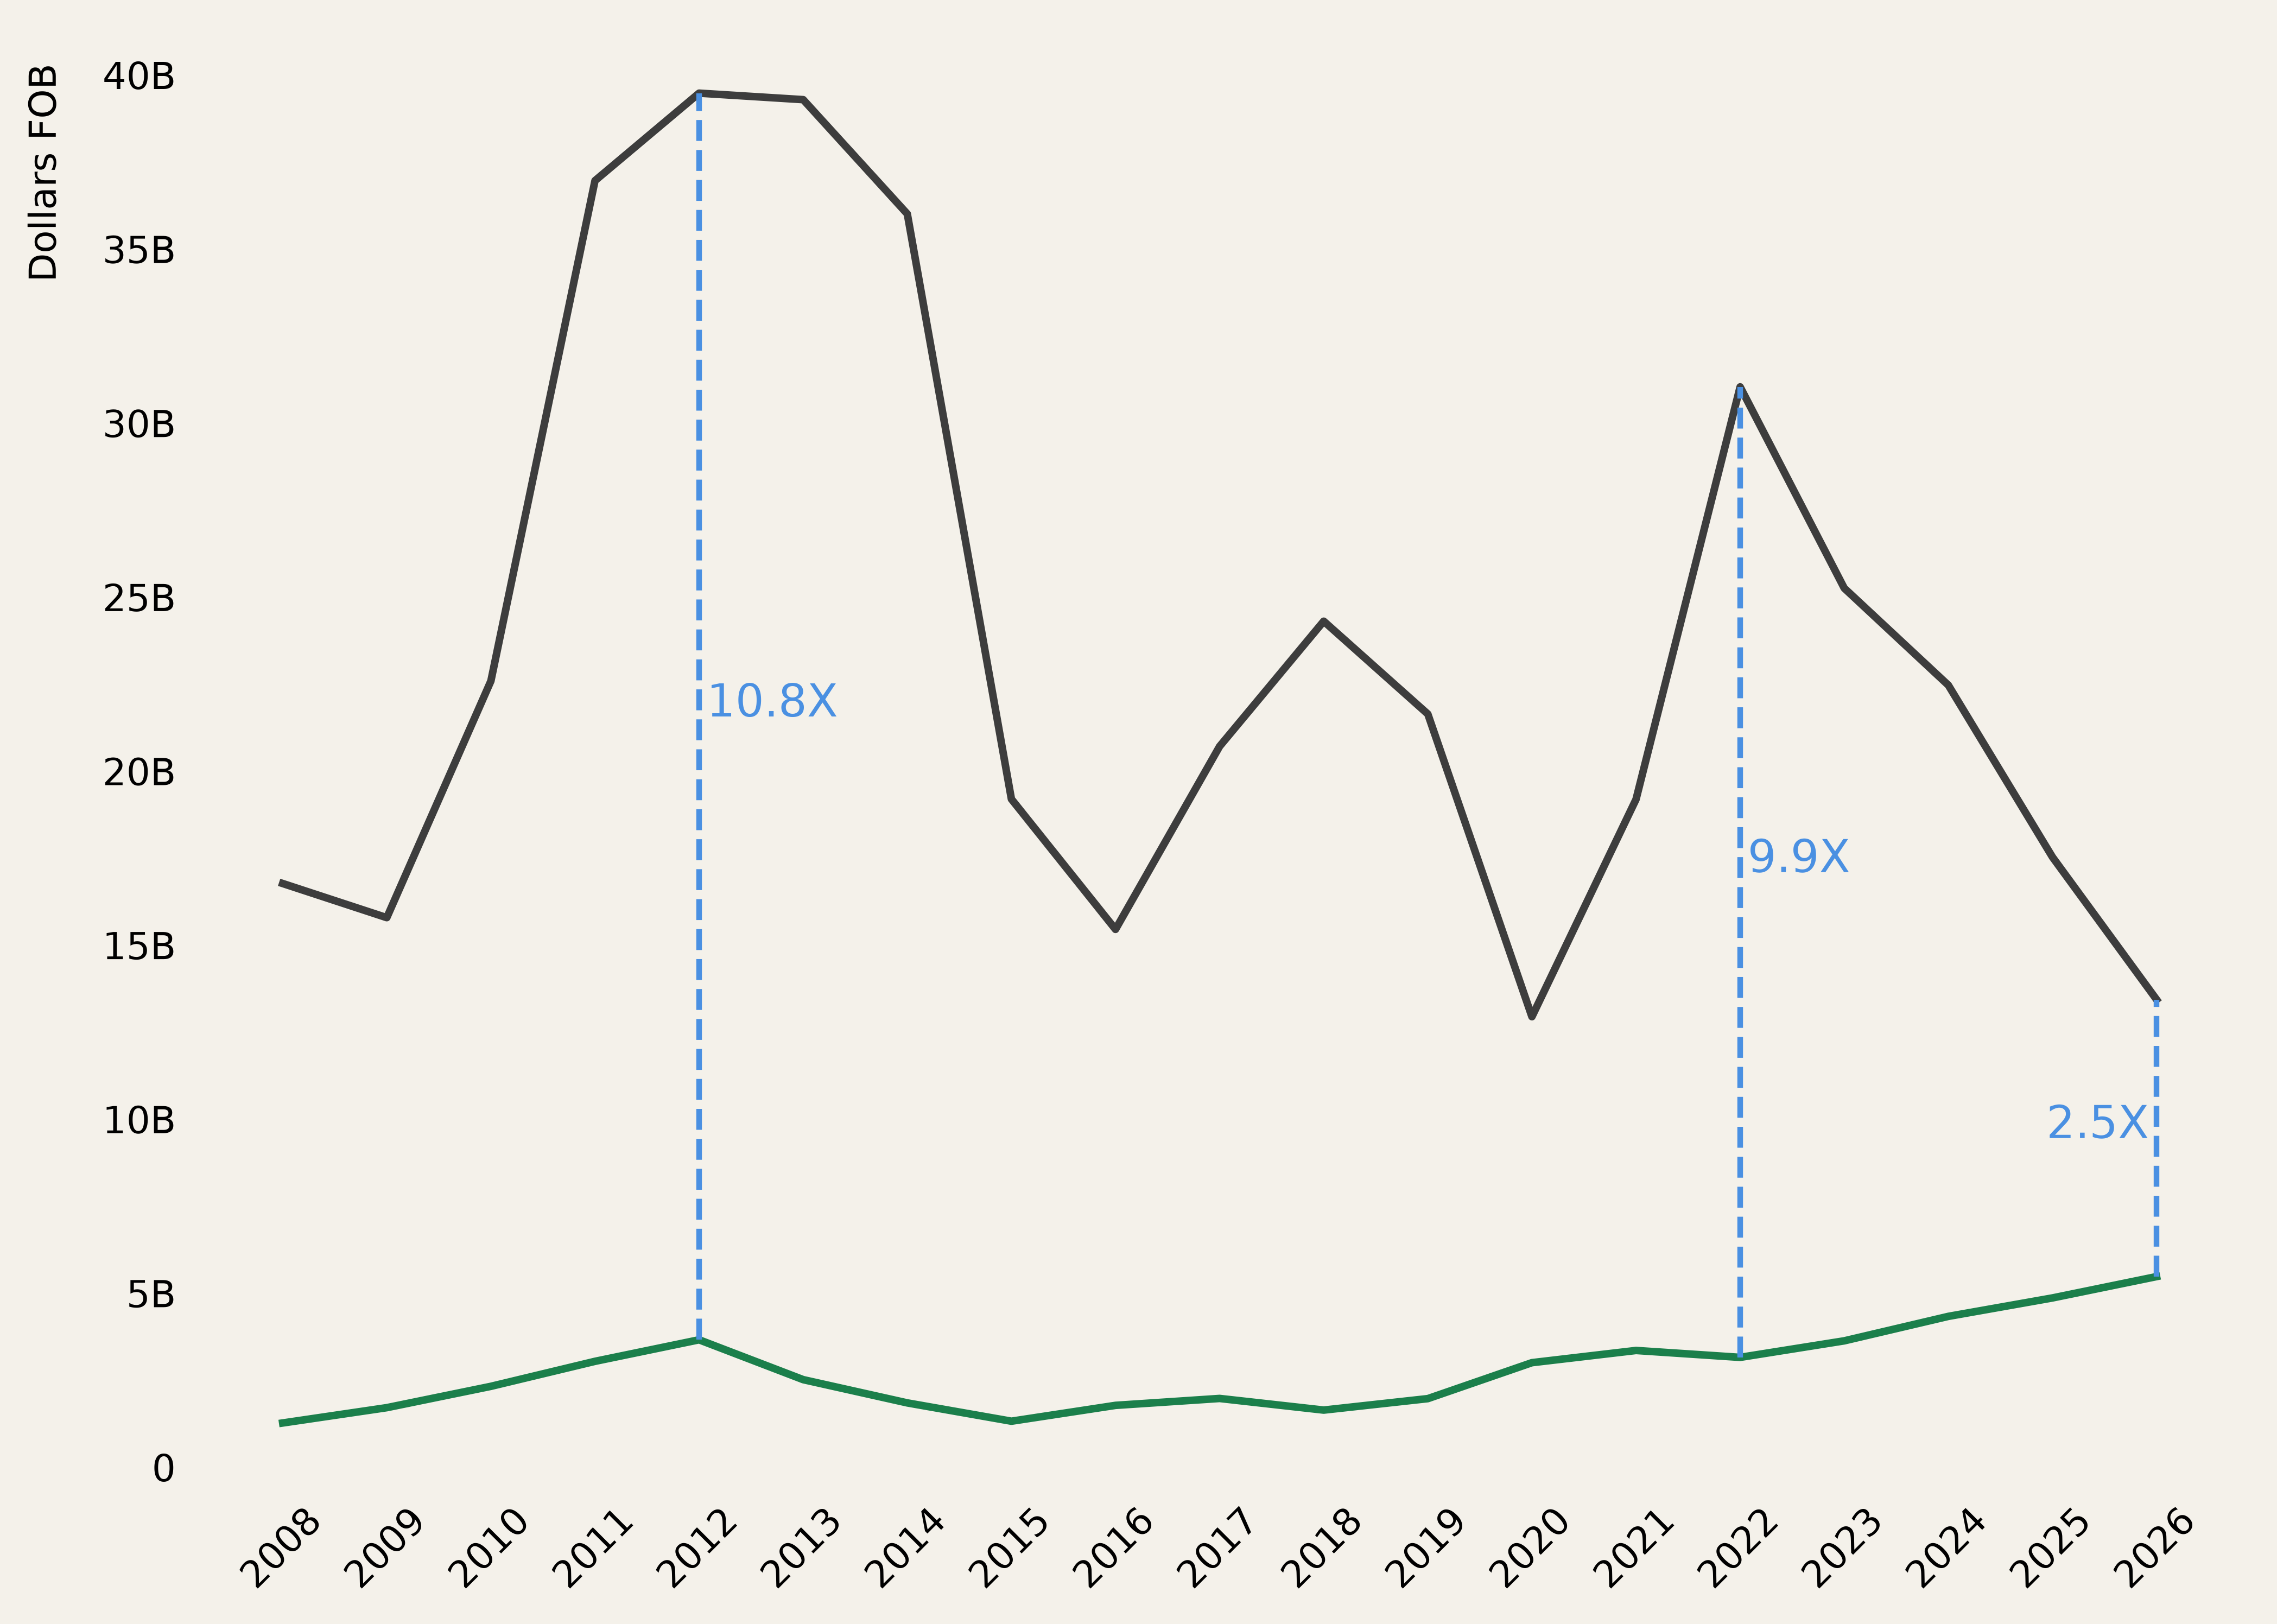

In [88]:
background = "#F4F1EA"
blue = "#4a90e2"
x_axis = final.index

value_colors = {
    "Combustibles y aceites minerales y sus productos": "#3D3D3D",
    "Perlas finas, piedras y metales preciosos": "#1B7F4B",
}

fig, ax = plt.subplots(figsize=(9.8, 7.0), dpi=500)
fig.patch.set_facecolor(background)
ax.patch.set_facecolor(background)

for column in final.columns:
    plt.plot(
        x_axis, final[column],  
        color=value_colors.get(column),
        linewidth=2
    )

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{int(x/1000000)}B" if x != 0 else "0"
    )
)

plt.xticks(x_axis, rotation=45)

plt.ylabel("Dollars FOB", labelpad=10, fontsize=10, y=0.9)

for side in ["top", "bottom", "left", "right"]:
    plt.gca().spines[side].set_visible(False)

for axis in ["y", "x"]:
    plt.tick_params(axis=axis, length=0)

gems = "Perlas finas, piedras y metales preciosos"
oil = "Combustibles y aceites minerales y sus productos"

for year in [2012, 2022, 2026]:
    difference = final.loc[year, oil] / final.loc[year, gems]
    ymin = final.loc[year, gems]
    ymax = final.loc[year, oil]

    text_loc = (ymin + ymax) / 2

    ha = "right" if year == 2026 else "left"

    x_offset = -2 if year == 2026 else 2

    plt.vlines(
        x=year, 
        ymin=ymin,
        ymax=ymax,
        color=blue,
        linestyle="--"
    )

    plt.annotate(
        f"{difference:.1f}X",
        xy=(year, text_loc),
        xytext=(x_offset, 0),
        textcoords="offset points",
        color=blue,
        ha=ha,
        fontsize=12,
    )

plt.show()